In [1]:
import pandas as pd          # classification model that predicts the amount of survivors from the Titanic
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = pd.read_csv('titanic.csv')  # reads the 'titanic.csv' file

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
data.head()   # prints info from first 5 rows

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
data.tail()   # prints infor from last 5 rows

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [8]:
data.describe()   # prints numerical info from all rows

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
data.shape   # shows number of rows and columns

(891, 12)

In [10]:
data.isnull().sum()   # shows number of missing values in each row

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
data.corr(numeric_only=True)   # shows correlation between numerical columns

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


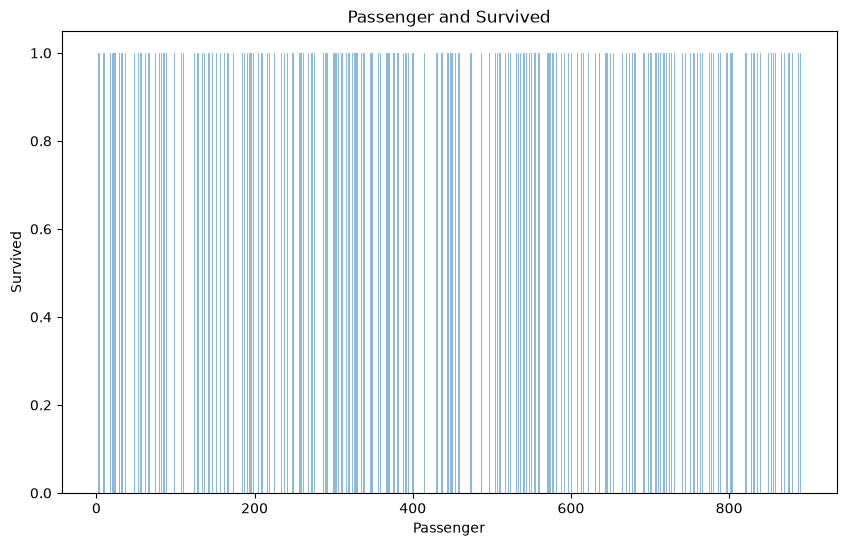

In [12]:
plt.figure(figsize=(10,6))
plt.bar(data['PassengerId'], data['Survived'], alpha=0.5)
plt.xlabel('Passenger')
plt.ylabel('Survived')
plt.title('Passenger and Survived')
plt.show()

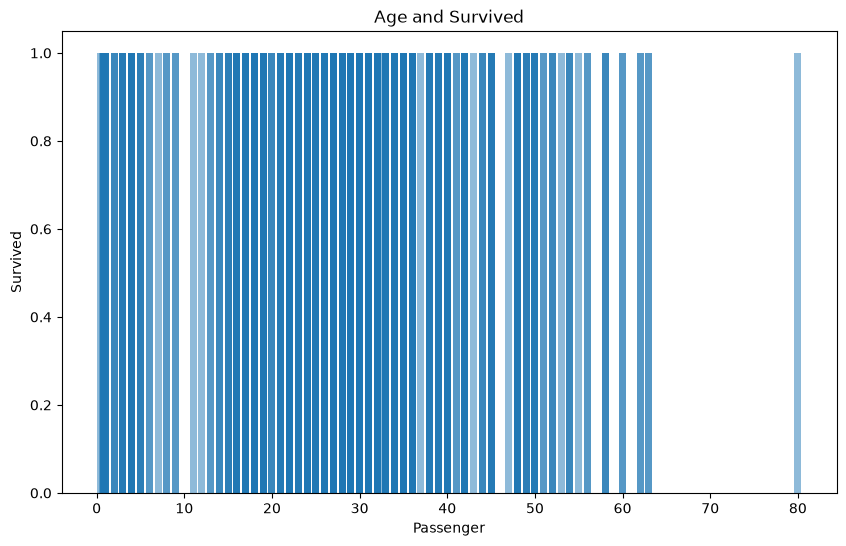

In [13]:
plt.figure(figsize=(10,6))
plt.bar(data['Age'], data['Survived'], alpha=0.5)
plt.xlabel('Passenger')
plt.ylabel('Survived')
plt.title('Age and Survived')
plt.show()

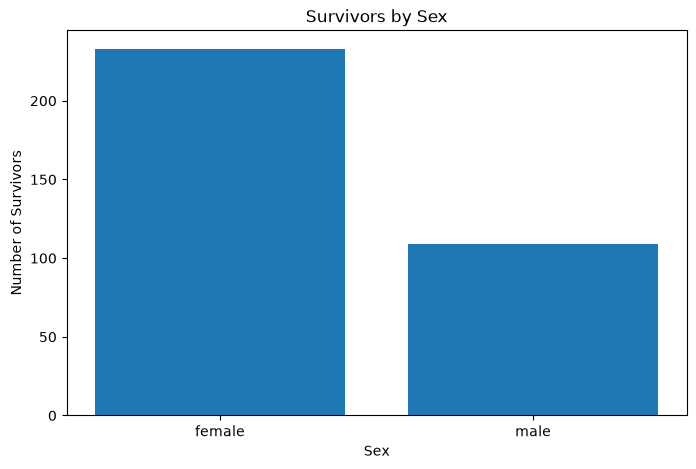

In [14]:

sex_survived = data.groupby('Sex')['Survived'].sum()   # counts survivors by sex

plt.figure(figsize=(8,5))   # figure size
plt.bar(sex_survived.index, sex_survived.values) # creates the bar graph
plt.xlabel('Sex')   # labels the x axis
plt.ylabel('Number of Survivors')   # labels the y axis
plt.title('Survivors by Sex')   # graph title
plt.show()   # displays the graph

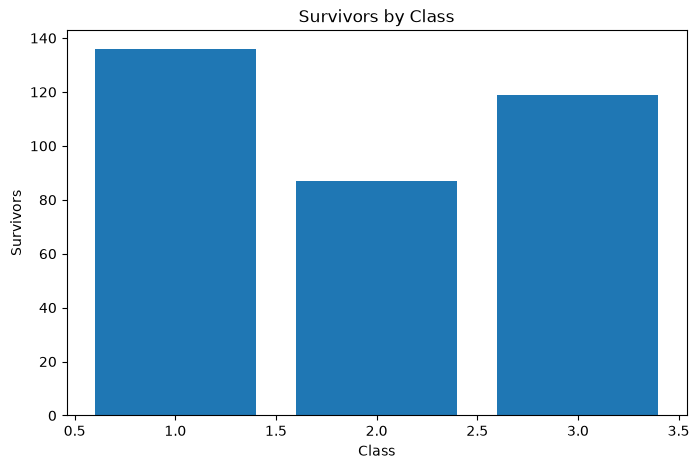

In [15]:
class_survived = data.groupby('Pclass')['Survived'].sum()   # counts survivors by class

plt.figure(figsize=(8,5))   # figure size
plt.bar(class_survived.index, class_survived.values)   # bar graph / gives class labels / gives survivor count

plt.xlabel('Class')   # X title
plt.ylabel('Survivors')   # Y title
plt.title('Survivors by Class')   # title of graph
plt.show()   # show graph





In [16]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'] # list of features

X = data[features]   # stores input data
y = data['Survived']   # stores predict target

X.head()   # shows first 5 rows



,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [17]:
from sklearn.model_selection import train_test_split   # imports splitting tool/function

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)   # splits the data

In [18]:
X_train.shape   # shows training data size

X_test.shape   # shows testing data size

(179, 7)

In [19]:
data.isnull().sum()   # count missing values in each column
data['Age'] = data['Age'].fillna(data['Age'].median())   # fills missing ages with the median
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])   # fills missing ports

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']   # list of features

X = data[features]   # stores input data
y = data['Survived']   # stores the target

from sklearn.model_selection import train_test_split   # imports the tool

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)   # splits data

In [20]:
X_train.shape   # shows training data size

(712, 7)

In [21]:
X_test.shape   # shows testing data size

(179, 7)

In [22]:
data['Age'].isnull().sum()   # counts missing ages

np.int64(0)

In [23]:
data['Embarked'].isnull().sum()   # counts missing embarkation ports

np.int64(0)

In [24]:
data.isnull().sum()   # checks missing values in every column

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [25]:
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], dtype=int)   # converts text columns into numbers [get_dummies makes a new column for each category]

In [26]:
X.head()   # shows first 5 rows

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


In [27]:
from sklearn.model_selection import train_test_split   # imports the splitting tool

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)   # splits the new data

In [28]:
from sklearn.preprocessing import StandardScaler   # imports the scaling tool [scales the numeric values]

scaler = StandardScaler()   # creates the scaler

X_train = scaler.fit_transform(X_train)   # learns the scale and scales training data [learns to scale the averages and the spread of data]

X_test = scaler.transform(X_test)   # scales testing data using the training scale 

In [29]:
X_train.shape

(712, 10)

In [30]:
X_test.shape

(179, 10)

In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression() #creates the classification model

model.fit(X_train, y_train)  #trains the model


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [34]:
y_pred = model.predict(X_test) #predicts survival

print (y_pred)

[0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 1 0 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0 1 0 1 1
 0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0
 1 1 0 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 0 1 0 0 1 0]


In [42]:
from sklearn.metrics import precision_score  #imports precision score tool

precision = precision_score(y_test, y_pred)  #calculates precision score

print (precision)

0.7931034482758621


In [43]:
from sklearn.metrics import recall_score #imports recall score tool

recall = recall_score(y_test, y_pred) #calculates recall score

print (recall)

0.6666666666666666


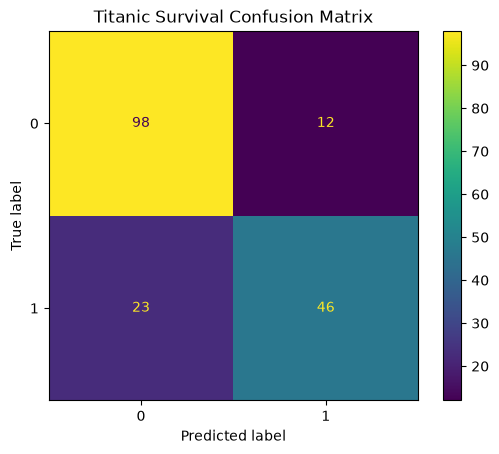

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay #imports Confusion Matrix tool

ConfusionMatrixDisplay.from_predictions(y_test, y_pred) #creates the confusion matrix
  
plt.title("Titanic Survival Confusion Matrix")
plt.show()

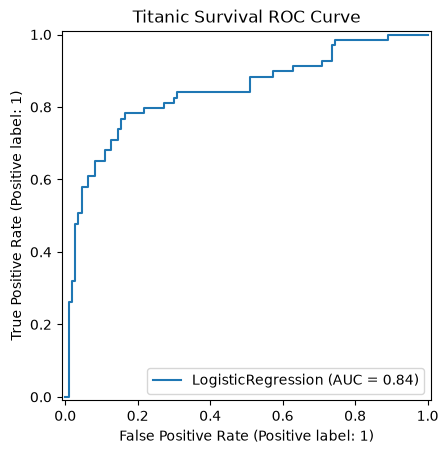

In [45]:
from sklearn.metrics import RocCurveDisplay #imports ROC Curve tool

RocCurveDisplay.from_estimator(model, X_test, y_test)  #creates ROC Curve

plt.title("Titanic Survival ROC Curve")
plt.show()